# CA3 Machine Learning Module Assignment

## Clustering Analysis of Bike-Sharing Data Using K-Means and Hierarchical Clustering

Introduction: This Activity aim to explores the application of machine learning techniques to two different datasets: Bike Sharing and Apple Inc. The first part focuses on unsupervised learning, using K-Means and Hierarchical Clustering to identify patterns in bike-sharing usage. The second part focuses on time series analysis, using historical Apple stock prices to investigate trends, potential seasonality and anomalies. ARIMA and/or SARIMA models will be applied to evaluate forecasting performance. Together, these analyses demonstrate how different machine learning and statistical techniques can be used to understand patterns and support decision-making in different domains.

The motivation for this analysis is to explore how data analytics and machine learning techniques can help understand bike rental behavior and spot patterns in bicycle demand. From a business and operational point of view, knowing when and under what conditions bike usage increases or decreases  can helps identify the factors linked to bicycle demand, supports better planning and management  of bike-sharing services, optimizes resource allocation and helps reduce operating costs. Similarly, understanding financial time series is important because stock prices change over time and are influenced by market conditions, economic events and investor behaviour. Analysing historical stock prices can provide insights into market trends, volatility and the challenges of predicting future values. 

This project deals with two different problem domains: urban mobility and financial time series analysis. Managing bike-sharing demand is an important challenge for urban transport systems, as changes in bike usage can affect bicycle availability, resource allocation and service management. Demand can also vary considerably depending on temporal and environmental conditions. Bean, Pojani and Corcoran (2021) analysed almost 100 million bike-sharing trips across 40 cities and found that bike usage varies according to factors such as time of day, rainfall and temperature. Understanding these variations can help identify usage patterns and support better planning and management of bike-sharing services.The second problem domain concerns the analysis and forecasting of financial time series. Stock prices frequently change due to economic conditions, market uncertainty and other external factors. These variations make it difficult to identify consistent patterns and predict future prices accurately. Time series analysis provides statistical methods to examine historical behaviour, identify potential trends and seasonality, and evaluate forecasting models.

The main objective of this project is to apply appropriate data analysis and machine learning techniques to identify meaningful patterns within the dataset. Exploratory Data Analysis (EDA) is used to understand the structure, distribution and relationships between variables. Data preprocessing and standardisation are applied where required to prepare the data for modelling. Principal Component Analysis (PCA) is used to reduce dimensionality and support the visualisation of patterns in the data. In addition, K-Means and Agglomerative Hierarchical Clustering are applied to investigate different bike usage segments. The clustering solutions are evaluated using the Silhouette Score and Davies-Bouldin Index, allowing the quality and separation of the identified groups to be compared. For the Apple Inc. Dataset, the objectives are: Explore historical stock price data and identify trends, potential seasonality and anomalies. Examine the stationarity of the time series and determine appropriate ARIMA/SARIMA parameters. Develop time series forecasting models using historical stock prices. Evaluate forecasting performance using appropriate error metrics. Discuss the strengths and limitations of the forecasting models.

The Bike Sharing dataset was selected because represents a practical real-world problem. It provides a suitable combination of numerical, categorical, temporal and environmental variables including season, year, month, hour, weather conditions, temperature, humidity and wind speed together with data on casual and registered users and the total number of bicycles rented it makes  apropriate for exploratory and unsupervised machine learning analysis that we can apply and compare different analytical techniques, including EDA, dimensionality reduction and clustering, helping explore how external conditions are related to bike usage supporting the understanding of urban bike-sharing demand.The Apple Inc. Dataset was selected because it provides historical financial data obtained from Yahoo Finance, covering approximately ten years. The dataset includes daily stock prices and trading volume, allowing the investigation of price movements over time. Its chronological structure makes it suitable for exploring trends, potential seasonality, anomalies and the application of ARIMA/SARIMA forecasting models.

## DATA PREPARATION 

We are starting by importing the libraries in order to access the tools required to load from the CSV file, process, analyse, and visualise the data. Then, we will examine the size of the dataset, the number of attributes, the number of observations, and check for missing values and duplicate rows. These steps are important to understand the context and characteristics of the dataset before performing the analysis. 

## Import libraries

In [1]:
import pandas as pd #for data mangement as dataframes
import numpy as np #for numerical operations
import matplotlib.pyplot as plt #for plots and visuals
import seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split
import warnings
warnings.filterwarnings('ignore')

In [2]:
import pandas as pd

hour = pd.read_csv("C:/Users/sonas/Preparation for ML assgnment Jupyter NB/hour.csv")

### Read the dataset

In [3]:
df = pd.read_csv('hour.csv')

In [4]:
df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


 # Characterisation of the dataset

This dataset containing 17379 row  with 17 atributes that give information about time (hr), season, weather conditions, temperature, humidity, workingday, weekday or a holiday, casual and registered users, also additional column with a  total number of bicycles rented as a target variable that need to be removed considering we are dealing with unsupervise ML modules (etc... From initial overview, it is noticed that there are not missing values either there are no duplicates values.

In [5]:
df.shape

(17379, 17)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  object 
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), object(1)
memory usage: 2.3+ MB


In [7]:
df.describe()

,instant,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.0000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,8690.0000,2.501640,0.502561,6.537775,11.546752,0.028770,3.003683,0.682721,1.425283,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088
std,5017.0295,1.106918,0.500008,3.438776,6.914405,0.167165,2.005771,0.465431,0.639357,0.192556,0.171850,0.192930,0.122340,49.305030,151.357286,181.387599
min,1.0000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,4345.5000,2.000000,0.000000,4.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000
50%,8690.0000,3.000000,1.000000,7.000000,12.000000,0.000000,3.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000
75%,13034.5000,3.000000,1.000000,10.000000,18.000000,0.000000,5.000000,1.000000,2.000000,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000
max,17379.0000,4.000000,1.000000,12.000000,23.000000,1.000000,6.000000,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000


In [8]:
df.isnull().sum()

instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

In [9]:
df.duplicated().sum() #There are no duplicates

np.int64(0)

In [10]:
df.isnull().sum() #checking the number of null values

instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

In [11]:
df.rename(columns={'cnt': 'Totalbikesrented',}, inplace=True)

## Exploratory Data Analysis (EDA)

We used different visualisations such as the correlation heatmap, time-series plots and bar charts to obtain a better understanding of the dataset before applying clustering techniques. The analysis was used to examine the distribution and relationships between variables, identify temporal and seasonal patterns, and investigate factors associated with bike rental behaviour.  For instance, the analysis showed differences in bike usage according to weather conditions, working days and user type, as well as changes in demand across months and years. The correlation analysis also identified strong relationships between temperature and perceived temperature. These findings supported the subsequent data preparation, feature selection and clustering stages and helped with the interpretation of the final clusters.

### Coorelation matrix

In [12]:
numeric_cols = df.select_dtypes(include='number').columns

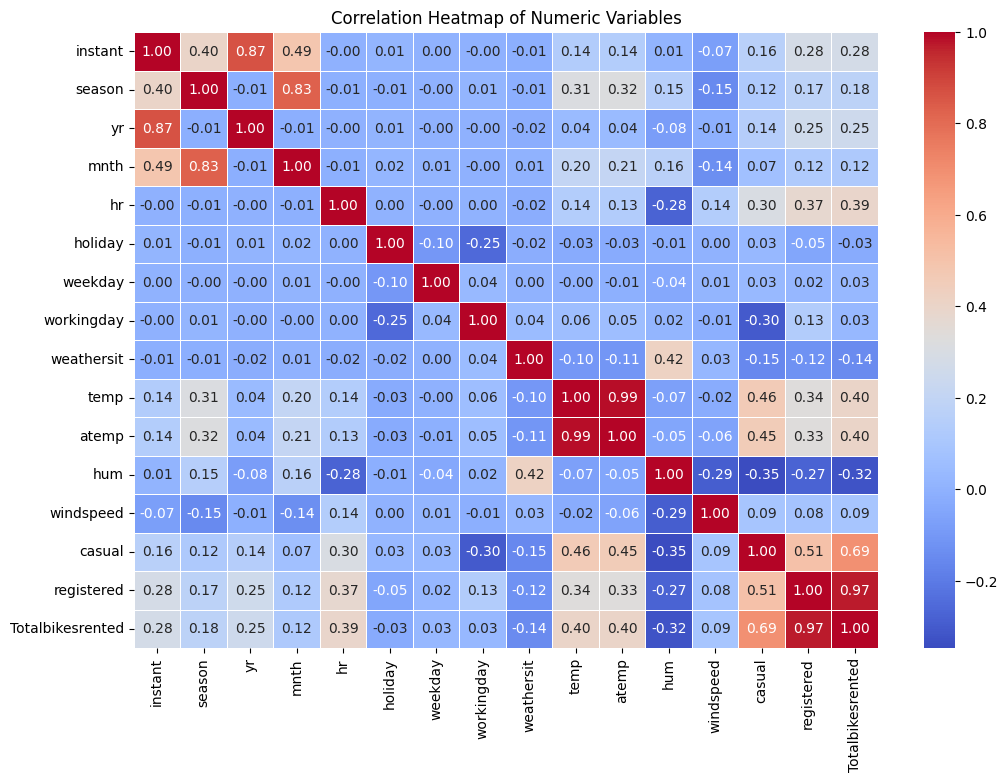

In [13]:
# Correlation heatmap
plt.figure(figsize=(12, 8))
corr = df[numeric_cols].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', linewidths=0.5)
plt.title('Correlation Heatmap of Numeric Variables')
plt.show()

The correlation heatmap shows several important relationships between the numerical variables. We observe a positive correlation (0.99)  between temperature (temp) and perceived temperature (atemp), indicating that these variables contain  similar information.

Total bike rentals are correlated with registered users (0.97) and moderately correlated with casual users (0.69). Temperature and perceived temperature  showed a positive correlation of 0.40 with total bike rentals, while humidity presents a negative correlation of -0.32. This suggests that warmer conditions are associated with higher bike usage, whereas higher humidity tends to be associated with lower demand. However, casual and registered should not be used as predictors if totalbikesrented is the target variable, as they are components of the total and could cause data leakage.

In [14]:
monthly_total = df.groupby(['yr', 'mnth'])['Totalbikesrented'].sum().unstack(level=0)

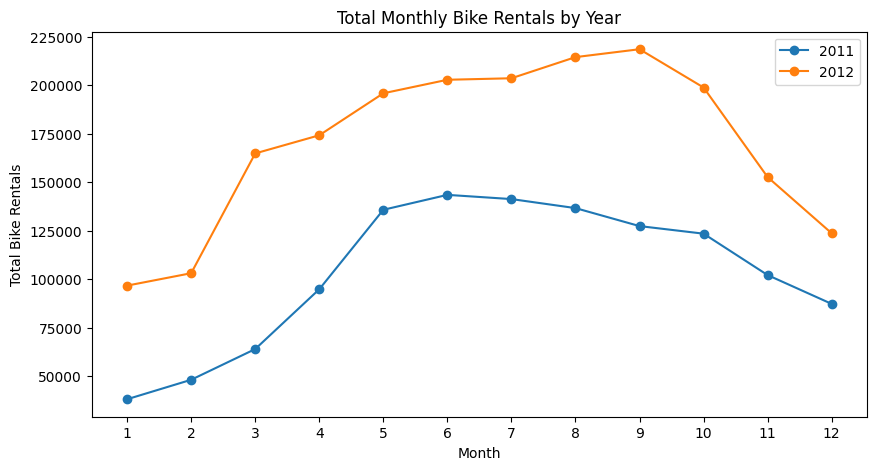

In [15]:
monthly_total.plot(
    kind='line',
    marker='o',
    figsize=(10, 5)
)

plt.xlabel('Month')
plt.ylabel('Total Bike Rentals')
plt.title('Total Monthly Bike Rentals by Year')
plt.xticks(range(1, 13))
plt.legend(['2011', '2012'])
plt.show()

The line chart shows the that bike usage was consistently higher in 2012 than in 2011 across all months, indicating a clear increase in the use of the bike-sharing service. In both years, rentals generally increased during the first part of the year, remained relatively high during the warmer months, and decreased towards the end of the year. In 2011, rentals reached their highest level around June, while in 2012 the peak occurred around September, with more than 200,000 rentals. The results indicate an increasing trend between the two years and a seasonal pattern in bike rental demand.

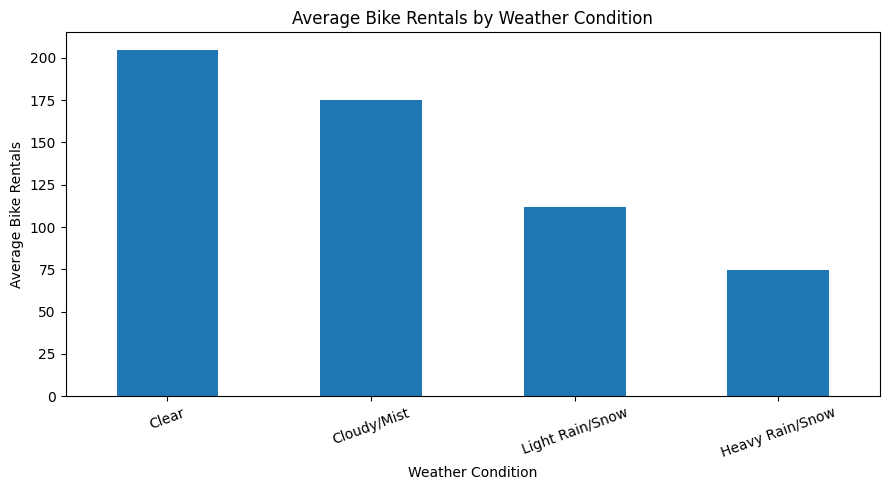

In [16]:
weather_labels = {
    1: 'Clear',
    2: 'Cloudy/Mist',
    3: 'Light Rain/Snow',
    4: 'Heavy Rain/Snow'
}

weather_rentals = df.groupby('weathersit')['Totalbikesrented'].mean()

weather_rentals.index = weather_rentals.index.map(weather_labels)

weather_rentals.plot(kind='bar', figsize=(9,5))

plt.title('Average Bike Rentals by Weather Condition')
plt.xlabel('Weather Condition')
plt.ylabel('Average Bike Rentals')
plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

 The bar chart shows the average number of bike rentals under different weather conditions. The highest average number of rentals occurs during clear weather, with approximately 200 rentals. This decreases to around 173 during cloudy or misty conditions and approximately 113 during light rain or snow. Heavy rain or snow shows the lowest average, at around 80 rentals. We can conclud that  bike rental demand tends to decrease as weather conditions become less favourable shoing that weather conditions are an important factor associated with bike usage.

## Clustering

##  Feature engineering - Encoding, Scaling

Feature Engineering is is the process of selecting, creating or modifying features like input variables or data to help machine learning models learn patterns more effectively. The goal is to improve model performance, ensure compatibility with machine learning algorithms, and capture meaningful patterns within the fisheries sustainability and revenue dataset.

Here, we identify different types of conditions under which bike-sharing activity occurs. Keeping environmental and time characteristics to identify clusters. 

We have removed the target variable  'Totalbikesrented' because we want to use unsupervised model that find patterns within the data to make clusters

In [17]:
features = [
    'hr',
    'temp',
    'hum',
    'windspeed'
]

## Feature Transformation

In [18]:
from sklearn.preprocessing import StandardScaler

X = df[features]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [19]:

X_scaled = np.asarray(X_scaled)

Machine learning algorithms cannot directly interpret text values, so encoding is required.

## K-Means Clustering Implementation

In [20]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score

results = []

for k in range(2, 9):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_scaled)

    silhouette = silhouette_score(X_scaled, labels)
    db = davies_bouldin_score(X_scaled, labels)

    results.append([k, silhouette, db])

### The differences between silhouette score and Davies-Bouldin index 

In [21]:
results

[[2, 0.25626134704899045, 1.541882734813255],
 [3, 0.24960381728294723, 1.4486748095297532],
 [4, 0.2538974860291746, 1.2857627578157973],
 [5, 0.23934123571576169, 1.3239100211134427],
 [6, 0.24093119588343723, 1.2805620633439243],
 [7, 0.23820963898453845, 1.2352594753733388],
 [8, 0.2380811923302025, 1.1854383162874385]]

We evaluated clustering performance  by testing K values from 2 to 10 using the Silhouette Score and Davies-Bouldin Index. When comparing the results, both evaluation metrics indicate that K=9 provides the strongest clustering performance among the tested solutions. K=9 achieved the highest Silhouette Score (0.1925) and the lowest Davies–Bouldin Index (1.5212). Therefore, K=9 was selected as the best option among those tested. Therefore, K=9 was selected as the best option among those tested. However, the Silhouette Score (0.1925) was relatively close to zero, indicating weak separation between the clusters. This suggests that some observations may share similar characteristics, making it difficult to identify clearly separated groups. We used this method  to assess how compact and well separated the clusters were.  The silhouette coefficient values change from -1 to +1 and higher values represent a better quality of cluster. In contrast, lower Davies–Bouldin values indicate better clustering performance. (Leiture 1).

### KMeans

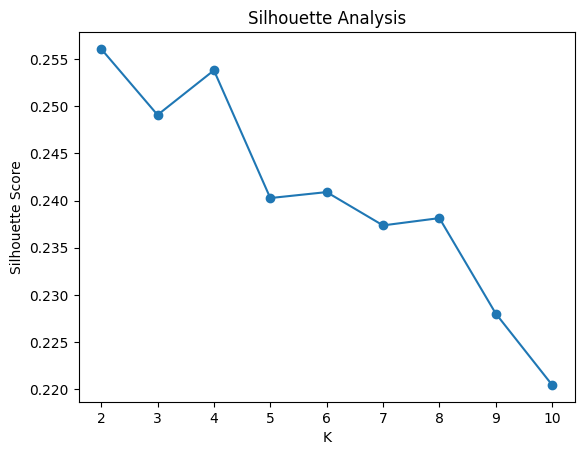

In [22]:
from sklearn.metrics import silhouette_score

scores = []
K_range = range(2, 11)

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42)
    labels = km.fit_predict(X_scaled)
    scores.append(silhouette_score(X_scaled, labels))

plt.plot(K_range, scores, marker='o')
plt.xlabel("K")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Analysis")
plt.show()

The Silhouette Analysis was used to evaluate different numbers of clusters from K=2 to K=10. The highest Silhouette Score was obtained at K=10, with a value of approximately 0.176. This indicates that K=10 provided the best result according to the Silhouette criterion among the tested solutions. However, all Silhouette Scores were relatively low and close to each other, suggesting limited separation and some overlap between the clusters

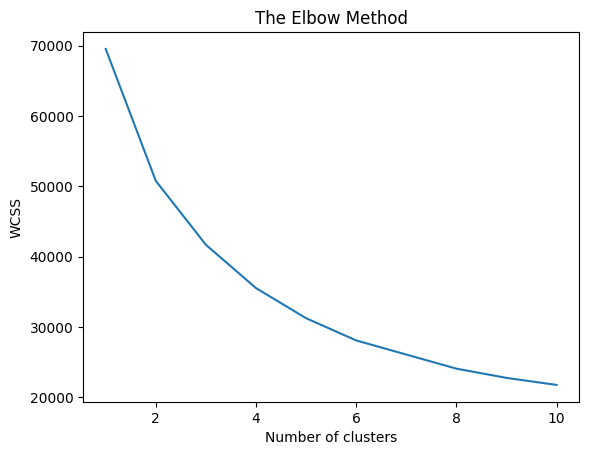

In [23]:
from sklearn.cluster import KMeans
wcss = []
for i in range(1, 11):
    kmeans = KMeans(n_clusters = i, init = 'k-means++', random_state = 42)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)
plt.plot(range(1, 11), wcss)
plt.title('The Elbow Method')
plt.xlabel('Number of clusters')
plt.ylabel('WCSS')
plt.show()

### How many clusters (K) should I use in K-Means?

### On the X-axis we have the number of clusters (K). On the Y-axis we have WCSS (Within-Cluster Sum of Squares), which measures how spread out the points are within their own clusters.

We have three methods evaluating different things:  
Elbow: looks for where adding clusters stops reducing WCSS significantly.  
Silhouette: looks for clusters that are more internally cohesive and separate from each other.  
Davies-Bouldin: looks for compact and separated clusters; the smaller, the better.  
That's why they're not required to pick the same K. 
Elbow → sugere aproximadamente 4–6 clusters
Silhouette → melhor em K=9 (0.1925)
Davies-Bouldin → melhor em K=9 (1.5212)

The Elbow Method was used to explore the appropriate number of clusters for K-Means. The WCSS decreased substantially as the number of clusters increased from 1 to approximately 4–6 clusters, after which the reduction became more gradual. However, the elbow was not clearly defined. Therefore, the Elbow Method was considered together with the Silhouette Score and Davies-Bouldin Index when selecting the final number of clusters

In [24]:
kmeans_final = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

kmeans_labels = kmeans_final.fit_predict(X)

df["Cluster"] = kmeans_labels

In [25]:
kmeans_labels

array([1, 1, 1, ..., 0, 0, 0], shape=(17379,), dtype=int32)

In [26]:
df["Cluster"].value_counts().sort_index()

Cluster
0    3640
1    2862
2    3638
3    3646
4    3593
Name: count, dtype: int64

In [27]:
cluster_summary = df.groupby("Cluster")[features].mean()

cluster_summary

,hr,temp,hum,windspeed
Cluster,,,,
0,21.000000,0.497522,0.626374,0.185137
1,1.483229,0.458686,0.710245,0.156529
2,11.001374,0.519010,0.579447,0.207668
3,15.999726,0.558886,0.506857,0.232599
4,6.019482,0.441842,0.732497,0.160944


Elbow Method: identify the point where the rate of decrease in WCSS sharply changes. Here, we find at k=5 the line drops sharply, se we use 5 clusters

Based on Silhouette Score, which tells how close are the clusters, we found we need 5 clusters to Cluster bike usage

Using PCA to plot because we have several clustering variables,

PCA Visualisation

In [28]:
#from sklearn.decomposition import PCA
# Apply PCA
#pca = PCA(n_components=6)

#X_pca = pca.fit_transform(X_scaled)

# Check explained variance
#print("Explained variance ratio:", pca.explained_variance_ratio_)
#print("Total variance explained:", pca.explained_variance_ratio_.sum())



In [29]:
# Create dataframe for plotting
#pca_df = pd.DataFrame(
#    X_pca[:, :2],
#    columns=['PC1', 'PC2']
#)

# Add cluster labels
#pca_df['Cluster'] = df['Cluster'].values



In [31]:
# Plot
plt.figure(figsize=(10, 7))

for cluster in sorted(pca_df['Cluster'].unique()):

    cluster_data = pca_df[pca_df['Cluster'] == cluster]

    plt.scatter(
        cluster_data['PC1'],
        cluster_data['PC2'],
        label=f'Cluster {cluster}',
        alpha=0.5
    )

plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('K-Means Clusters Visualised Using PCA')
plt.legend()
plt.show()

NameError: name 'pca_df' is not defined

<Figure size 1000x700 with 0 Axes>

### para reverSó existe uma ressalva importante: esse gráfico mostra apenas PC1 e PC2, portanto não devemos concluir que toda a separação existente no espaço original aparece aqui. É uma visualização reduzida dos dados.

The PCA visualisation shows the nine clusters identified by K-Means projected onto the first two principal components. Some clusters show relatively distinct regions, particularly in parts of the PCA space. However, considerable overlap can also be observed between several clusters. This suggests that the dataset does not contain completely distinct groups and supports the relatively low Silhouette Score.

### Para reverSe sua decisão final for realmente K=9, precisamos gerar novamente essa visualização usando 9 clusters. A legenda então deverá mostrar Cluster 0 até Cluster 8.

In [32]:
cluster_profile = df.groupby('Cluster').mean(numeric_only=True)

cluster_profile

,instant,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,Totalbikesrented
Cluster,,,,,,,,,,,,,,,,
0,8676.884615,2.495879,0.501374,6.520604,21.000000,0.028846,2.995879,0.684066,1.385440,0.497522,0.477561,0.626374,0.185137,30.142308,155.664560,185.806868
1,8728.186233,2.511880,0.505590,6.567785,1.483229,0.028302,3.016771,0.680294,1.408106,0.458686,0.443055,0.710245,0.156529,6.075821,24.609015,30.684836
2,8661.595657,2.496152,0.500550,6.523364,11.001374,0.028862,3.000550,0.682518,1.461517,0.519010,0.494569,0.579447,0.207668,55.515118,166.130841,221.645959
3,8664.116018,2.495612,0.500549,6.519199,15.999726,0.028799,2.998629,0.683489,1.415524,0.558886,0.527845,0.506857,0.232599,71.926769,266.301700,338.228470
4,8727.895630,2.510994,0.505427,6.564709,6.019482,0.028945,3.009463,0.682716,1.452547,0.441842,0.428162,0.732497,0.160944,7.988032,128.107988,136.096020


PCA was used to reduce the dimensionality of the dataset while retaining most of the information. The first six principal components explained 93.76% of the total variance. Therefore, PCA provided a useful representation of the data while reducing the number of dimensions.

# Hierarchical Clustering

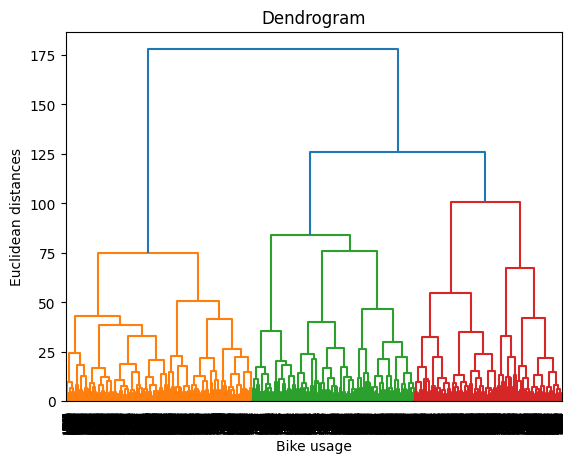

In [33]:
import scipy.cluster.hierarchy as sch
dendrogram = sch.dendrogram(sch.linkage(X_scaled, method = 'ward'))
plt.title('Dendrogram')
plt.xlabel('Bike usage')
plt.ylabel('Euclidean distances')
plt.show()

The dendrogram illustrates the hierarchical relationships between the observations in the Bike Sharing dataset using Ward’s linkage method and Euclidean distance. Observations with similar characteristics are progressively merged into clusters. The larger vertical distances between the main branches indicate that some groups are more distinct from each other. The dendrogram suggests the presence of approximately four main groups; however, the number of clusters is not completely clear from the visualisation alone. Therefore, additional evaluation using the Silhouette Score and Davies-Bouldin Index was used to assess the clustering performance.

In [34]:
# Import libraries
from sklearn.cluster import AgglomerativeClustering

# Create Hierarchical Clustering model with 5 clusters
hierarchical = AgglomerativeClustering(
    n_clusters=5,
    linkage='ward'
)

# Fit the model and create cluster labels
hierarchical_labels = hierarchical.fit_predict(X_scaled)

# Calculate Silhouette Score
sil_hierarchical = silhouette_score(
    X_scaled,
    hierarchical_labels
)

# Calculate Davies-Bouldin Index
db_hierarchical = davies_bouldin_score(
    X_scaled,
    hierarchical_labels
)

# Display results
print("Hierarchical Clustering Results")
print("Silhouette Score:", sil_hierarchical)
print("Davies-Bouldin Index:", db_hierarchical)

Hierarchical Clustering Results
Silhouette Score: 0.17787393030281715
Davies-Bouldin Index: 1.5169294501290242


We implemented Hierarchical Agglomerative using Ward linkage and five clusters. The algorithm achieved a Silhouette Score of 0.1059 and a Davies–Bouldin Index of 1.6507. The low Silhouette Score suggests weak separation between clusters, indicating that some observations may share similar characteristics. Furthermore, the Davies–Bouldin Index suggests that cluster compactness and separation could be improved

In [41]:
from sklearn.cluster import AgglomerativeClustering

hc = AgglomerativeClustering(
    n_clusters=4,
    metric='euclidean',
    linkage='ward'
)

y_hc = hc.fit_predict(X_scaled)

In [42]:
from sklearn.metrics import silhouette_score, davies_bouldin_score

silhouette = silhouette_score(X_scaled, y_hc)
db_index = davies_bouldin_score(X_scaled, y_hc)

print(f"Silhouette Score: {silhouette:.4f}")
print(f"Davies-Bouldin Index: {db_index:.4f}")

Silhouette Score: 0.1984
Davies-Bouldin Index: 1.4981


In [43]:
df['hc_cluster'] = y_hc

In [44]:
from sklearn.decomposition import PCA
import pandas as pd
import matplotlib.pyplot as plt

# PCA to 2 dimensions
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

# Create dataframe
pca_hc = pd.DataFrame(
    X_pca,
    columns=['PC1', 'PC2']
)

# Add hierarchical cluster labels
pca_hc['cluster'] = y_hc


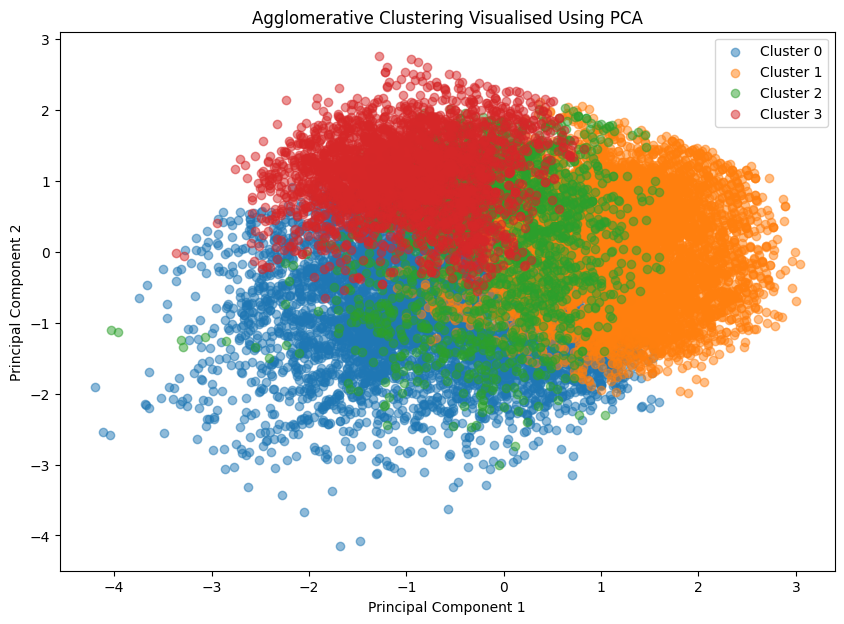

In [45]:
plt.figure(figsize=(10, 7))

for cluster in sorted(pca_hc['cluster'].unique()):

    cluster_data = pca_hc[pca_hc['cluster'] == cluster]

    plt.scatter(
        cluster_data['PC1'],
        cluster_data['PC2'],
        label=f'Cluster {cluster}',
        alpha=0.5
    )

plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('Agglomerative Clustering Visualised Using PCA')
plt.legend()
plt.show()

We used K-Means and Hierarchical Agglomerative Clustering on this dataset to identify patterns, knowing that these algorithms allow their performance to be compared and helps identify which method provides more meaningful segmentation of bike-sharing observations. Firstly, we used K-Means considering the size of the dataset that contain approximately 17.379 observations which is quite large  and K-Means can analyse large datasets efficiently and group observations with similar characteristics. By K-Means, different numbers of clusters can be tested, helping to identify a suitable number of groups using evaluation metrics such as the Silhouette Score and Davies–Bouldin Index. In contrast, Hierarchical Agglomerative Clustering was used because it applies a different approach by progressively combining similar observations into larger groups and it can provide a dendrogram to help visualise the clustering structure.

The results show that K-Means performed better than Hierarchical Agglomerative Clustering on the Bike Sharing Dataset. K-Means, using nine clusters, achieved a higher Silhouette Score (0.1925) compared with Hierarchical Clustering, which used five clusters and obtained a score of 0.1059. In addition, K-Means achieved a lower Davies–Bouldin Index (1.5212) than Hierarchical Clustering (1.6507), suggesting better cluster compactness and separation. However, both algorithms produced relatively low Silhouette Scores, indicating weak separation between clusters. Furthermore, the algorithms were evaluated using different numbers of clusters, which may influence the results. Therefore, although K-Means achieved better evaluation scores in these experiments, further comparison using the same number of clusters would provide a more reliable assessment of their performance.

 Conclusion: This assessment investigated bike-sharing patterns using unsupervised machine learning and time-series analysis. The exploratory analysis identified important temporal, weather-related and user-related patterns in bike demand. The clustering analysis compared K-Means and Agglomerative Hierarchical Clustering using the Silhouette Score and Davies-Bouldin Index etc... etc...

### Fuzzy C-Means


In [50]:
import skfuzzy as fuzz

# Transpose the data matrix so that each row represents a feature and each column represents a data point. 
# The skfuzzy cmeans() function expects input in this format.

X_fcm = X_scaled.T

# Assume the number of clusters
n_clusters = 4

# Initilise the model object
cntr, u, u0, d, jm, p, fpc = fuzz.cluster.cmeans(X_fcm, c=n_clusters, m=2, error=0.005, maxiter=1000, init=None, seed=42)

# pick highest membership
fcm_labels = np.argmax(u, axis=0)

In [51]:
X_fcm

array([[-1.67000398, -1.52537422, -1.38074446, ...,  1.36722104,
         1.51185081,  1.65648057],
       [-1.33464759, -1.4385164 , -1.4385164 , ..., -1.23077877,
        -1.23077877, -1.23077877],
       [ 0.9473725 ,  0.89553869,  0.89553869, ..., -0.14113744,
        -0.34847267,  0.11803159],
       [-1.55388851, -1.55388851, -1.55388851, ..., -0.21169121,
        -0.45609864, -0.45609864]], shape=(4, 17379))

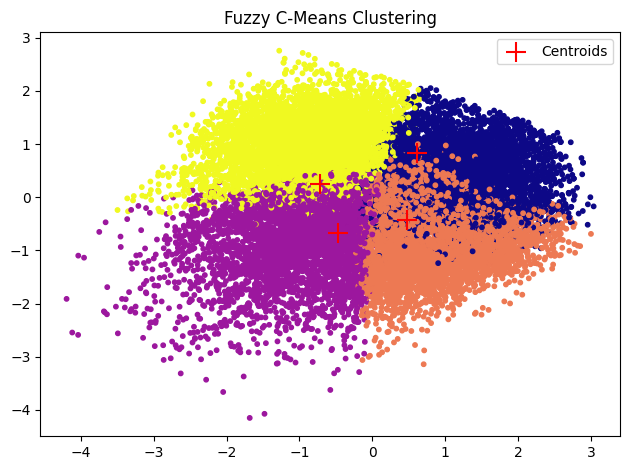

In [52]:

# Plot FCM results

plt.scatter(X_pca[:, 0], X_pca[:, 1], c=fcm_labels, cmap="plasma", s=10)
plt.scatter(cntr[:, 0], cntr[:, 1], c="red", marker="+", s=200, label="Centroids")
plt.title("Fuzzy C-Means Clustering")

plt.legend()

plt.tight_layout()
plt.show()

In [53]:
print("Shape of X_scaled:", X_scaled.shape)

print("Unique values in feature 1:",
      np.unique(X_scaled[:, 0]))

print("Unique values in feature 2:",
      np.unique(X_scaled[:, 1]))

print("Number of centroids:", cntr.shape[0])

print("Cluster distribution:")
print(np.unique(fcm_labels, return_counts=True))

Shape of X_scaled: (17379, 4)
Unique values in feature 1: [-1.67000398 -1.52537422 -1.38074446 -1.23611469 -1.09148493 -0.94685517
 -0.8022254  -0.65759564 -0.51296588 -0.36833611 -0.22370635 -0.07907659
  0.06555318  0.21018294  0.3548127   0.49944247  0.64407223  0.78870199
  0.93333176  1.07796152  1.22259128  1.36722104  1.51185081  1.65648057]
Unique values in feature 2: [-2.47720451 -2.3733357  -2.26946689 -2.16559808 -2.06172927 -1.95786045
 -1.85399164 -1.75012283 -1.64625402 -1.54238521 -1.4385164  -1.33464759
 -1.23077877 -1.12690996 -1.02304115 -0.91917234 -0.81530353 -0.71143472
 -0.60756591 -0.50369709 -0.39982828 -0.29595947 -0.19209066 -0.08822185
  0.01564696  0.11951577  0.22338458  0.3272534   0.43112221  0.53499102
  0.63885983  0.74272864  0.84659745  0.95046626  1.05433508  1.15820389
  1.2620727   1.36594151  1.46981032  1.57367913  1.67754794  1.78141675
  1.88528557  1.98915438  2.09302319  2.196892    2.30076081  2.40462962
  2.50849843  2.61236725]
Number of c